# Multi-manager portfolio diversification and historical stress study

**Decision:** Does shifting 10 percentage points from Sue (large growth) to
Ellen (small value) improve the portfolio's historical diversification?

The study compares Current and Proposed using monthly returns for 2021–2025,
with a separate January–December 2022 historical replay. Manager identities and
allocations are fictional. Returns are research portfolio proxies from the
Kenneth French Data Library, not actual manager track records.

This is a retrospective comparison, not a forecast or out-of-sample test.
Both portfolios rebalance to target weights before each month. No extra fees,
trading costs, taxes, borrowing or external cash flows are modelled.
Ellen's proposed allocation is conditional on completing onboarding.

Run cells from top to bottom. A DataFrame is a table; a Series is one column.
CSV and chart exports contain analytical results; explanatory material stays here.

In [1]:
# 1. Imports and file locations
from pathlib import Path
import sys
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "manager_returns.csv").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open the repository folder or its Python project folder before running this study.")
DATA_DIR = REPO_ROOT / "data"
PROJECT_DIR = REPO_ROOT / "02_Python_Portfolio_Study"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.options.display.float_format = "{:,.4f}".format
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})
print("Data folder:", DATA_DIR)
print("pandas:", pd.__version__, "| NumPy:", np.__version__)

Matplotlib is building the font cache; this may take a moment.


Data folder: <original local project folder>
pandas: 3.0.6 | NumPy: 2.5.4


## 2. Load four input tables

`read_csv()` loads a CSV into a DataFrame. `parse_dates` converts dates into
values Python can sort and filter. Returns are stored as decimals: 0.05 = 5%.
The benchmark is total U.S. market return (Mkt-RF + RF), not Mkt-RF alone.

In [2]:
managers = pd.read_csv(DATA_DIR / "managers.csv")
returns_long = pd.read_csv(DATA_DIR / "manager_returns.csv", parse_dates=["month_end"])
allocations = pd.read_csv(DATA_DIR / "allocations.csv")
market = pd.read_csv(DATA_DIR / "market_data.csv", parse_dates=["month_end"])
display(managers[["manager_id", "manager_name", "strategy_style", "status"]])
display(returns_long.head())

,manager_id,manager_name,strategy_style,status
0,M01,Frank,Small growth,Allocated
1,M02,Mary,Small neutral,Allocated
2,M03,Ellen,Small value,Candidate
3,M04,Sue,Large growth,Allocated
4,M05,Dave,Large neutral,Allocated
5,M06,Richard,Large value,Allocated


,month_end,manager_id,return_decimal
0,2021-01-31,M01,0.0549
1,2021-01-31,M02,0.0504
2,2021-01-31,M03,0.1052
3,2021-01-31,M04,-0.0059
4,2021-01-31,M05,-0.0059


## 3. Validate inputs before calculating

An `assert` stops execution if an assumption is false. These checks reject
missing or duplicated records; they do not fill missing returns with zero.
The expected month-end calendar detects a missing month even when the total
number of rows happens to be correct. The frozen case study has six managers.

In [3]:
expected_months = pd.period_range("2021-01", "2025-12", freq="M").to_timestamp("M")
expected_ids = ["M01", "M02", "M03", "M04", "M05", "M06"]
scenarios = ["Current", "Proposed"]

assert managers["manager_id"].is_unique, "Duplicate manager ID"
assert sorted(managers["manager_id"].tolist()) == expected_ids, "Unexpected manager list"
assert not managers[["manager_name", "strategy_style"]].isna().any().any()
assert not returns_long.duplicated(["month_end", "manager_id"]).any(), "Duplicate return record"
assert not returns_long[["month_end", "manager_id", "return_decimal"]].isna().any().any()
assert set(returns_long["manager_id"]) == set(expected_ids)
assert np.isfinite(returns_long["return_decimal"]).all(), "Non-finite return"
assert (returns_long["return_decimal"] >= -1).all(), "Return below -100%"

expected_keys = pd.MultiIndex.from_product([expected_months, expected_ids])
actual_keys = pd.MultiIndex.from_frame(returns_long[["month_end", "manager_id"]])
assert len(expected_keys.difference(actual_keys)) == 0, "Missing manager-month"
assert len(actual_keys.difference(expected_keys)) == 0, "Unexpected date or manager"
assert len(returns_long) == 360

assert not allocations.duplicated(["scenario", "manager_id"]).any()
assert not allocations[["scenario", "manager_id", "target_weight"]].isna().any().any()
assert set(allocations["scenario"]) == set(scenarios)
assert np.isfinite(allocations["target_weight"]).all()
assert allocations["target_weight"].between(0, 1).all()
for scenario in scenarios:
    rows = allocations[allocations["scenario"] == scenario]
    assert sorted(rows["manager_id"].tolist()) == expected_ids
    assert np.isclose(rows["target_weight"].sum(), 1, rtol=0, atol=1e-8)

assert market["month_end"].is_unique
assert pd.DatetimeIndex(market["month_end"].sort_values()).equals(expected_months)
market_columns = ["market_return_decimal", "mkt_excess_decimal", "rf_decimal"]
assert not market[market_columns].isna().any().any()
assert np.isfinite(market[market_columns].to_numpy()).all()
assert (market["market_return_decimal"] >= -1).all()
assert np.allclose(market["market_return_decimal"],
                   market["mkt_excess_decimal"] + market["rf_decimal"], rtol=0, atol=1e-8)
assert managers["benchmark_id"].eq("US_MARKET").all(), "Benchmark mapping changed"
print("Input checks passed: 6 managers, 60 months, 360 returns, both allocations total 100%.")

Input checks passed: 6 managers, 60 months, 360 returns, both allocations total 100%.


## 4. Reshape returns and calculate monthly portfolio returns

`pivot()` turns the long table into one column per manager. `reindex()` puts
weights in the same order as return columns. Aligning by ID prevents assigning
a manager someone else's weight.

Monthly portfolio return = sum of (beginning-of-month weight × manager return).
Fixed weights imply monthly rebalancing. These are not buy-and-hold results.

In [4]:
manager_returns = returns_long.pivot(index="month_end", columns="manager_id", values="return_decimal")
manager_returns = manager_returns.reindex(index=expected_months, columns=expected_ids)
manager_returns.index.name = "month_end"
weights = allocations.pivot(index="manager_id", columns="scenario", values="target_weight")
weights = weights.reindex(index=expected_ids, columns=scenarios)
manager_names = managers.set_index("manager_id")["manager_name"].reindex(expected_ids)

portfolio_returns = pd.DataFrame(index=manager_returns.index)
for scenario in scenarios:
    weighted_returns = manager_returns.multiply(weights[scenario], axis="columns")
    portfolio_returns[scenario] = weighted_returns.sum(axis=1)

benchmark = market.set_index("month_end")["market_return_decimal"].reindex(expected_months)
portfolio_returns["US market"] = benchmark
portfolio_returns.index.name = "month_end"
display(weights.rename(index=manager_names.to_dict()).mul(100).round(1))
display(portfolio_returns.head())

scenario,Current,Proposed
manager_id,,
Frank,10.0000,10.0000
Mary,10.0000,10.0000
Ellen,0.0000,10.0000
Sue,40.0000,30.0000
Dave,25.0000,25.0000
Richard,15.0000,15.0000


,Current,Proposed,US market
month_end,,,
2021-01-31,0.0079,0.0190,-0.0007
2021-02-28,0.0507,0.0597,0.0281
2021-03-31,0.0332,0.0381,0.0317
2021-04-30,0.0450,0.0401,0.0495
2021-05-31,0.0094,0.0165,0.0030


## 5. Return, volatility and drawdown

- Cumulative return compounds monthly growth factors; it does not add returns.
- Annualized return is the compound annual growth rate (CAGR).
- Annualized volatility is sample monthly standard deviation × sqrt(12).
- Drawdown is the percentage fall from the previous wealth peak. Maximum
  drawdown is shown as a negative number; closer to zero is a smaller loss.

The initial wealth of 1 is included before the first month, so a loss in that
first month is measured correctly. Monthly data miss intra-month drawdowns.
The conventional sqrt(12) scaling does not model serial correlation.

In [5]:
def wealth_and_drawdown(monthly_returns):
    """Build a wealth index with initial value 1, then measure peak-to-trough losses."""
    wealth = (1 + monthly_returns).cumprod()
    initial_date = monthly_returns.index.min() - pd.offsets.MonthEnd(1)
    initial_row = pd.DataFrame(1.0, index=[initial_date], columns=wealth.columns)
    wealth = pd.concat([initial_row, wealth])
    wealth.index.name = "month_end"
    drawdown = wealth / wealth.cummax() - 1
    return wealth, drawdown

wealth, drawdown = wealth_and_drawdown(portfolio_returns)
number_of_months = len(portfolio_returns)
metrics = pd.DataFrame({
    "cumulative_return": wealth.iloc[-1] - 1,
    "annualized_return": wealth.iloc[-1] ** (12 / number_of_months) - 1,
    "annualized_volatility": portfolio_returns.std(ddof=1) * np.sqrt(12),
    "maximum_drawdown": drawdown.min()
})
metrics.index.name = "portfolio"
display(metrics.mul(100).round(2).rename(columns=lambda x: x + "_pct"))

,cumulative_return_pct,annualized_return_pct,annualized_volatility_pct,maximum_drawdown_pct
portfolio,,,,
Current,82.3400,12.7700,15.7500,-21.9500
Proposed,81.2800,12.6300,16.1300,-20.6500
US market,84.6700,13.0500,15.4200,-24.8400


## 6. Diversification: correlations in the full sample and in 2022

Correlation measures how returns move together, on a scale from -1 to +1.
A lower correlation can help diversification, but it does not guarantee a
lower-risk portfolio: the size and volatility of the allocation matter too.
The 2022 estimate uses only 12 observations and is particularly uncertain.

In [6]:
correlation = manager_returns.corr()
stress_manager_returns = manager_returns.loc["2022-01-01":"2022-12-31"]
stress_correlation = stress_manager_returns.corr()
assert len(stress_manager_returns) == 12
candidate_correlations = pd.DataFrame({
    "comparison": ["Ellen vs Sue", "Ellen vs Current portfolio"],
    "full_sample_correlation": [
        manager_returns["M03"].corr(manager_returns["M04"]),
        manager_returns["M03"].corr(portfolio_returns["Current"])
    ],
    "correlation_2022": [
        stress_manager_returns["M03"].corr(stress_manager_returns["M04"]),
        stress_manager_returns["M03"].corr(portfolio_returns.loc["2022", "Current"])
    ]
})
display(candidate_correlations.round(3))

,comparison,full_sample_correlation,correlation_2022
0,Ellen vs Sue,0.5310,0.8000
1,Ellen vs Current portfolio,0.8210,0.9230


## 7. Contribution to portfolio volatility

Allocation share and risk share are different. A manager can contribute more
risk than their capital weight because of their volatility and relationship
with the other managers. This is the one more advanced calculation in the study.

`cov()` estimates how returns move together. Annual covariance = monthly sample
covariance × 12. For weights w and annual covariance C:

portfolio volatility = sqrt(w' C w)

manager contribution = weight × (C w) / portfolio volatility

Contributions sum to total volatility. Dividing each contribution by total
volatility gives a risk share summing to 100%. A hedging allocation can have a
negative contribution. These are historical, full-sample estimates, not forecasts.

In [7]:
annual_covariance = manager_returns.cov(ddof=1) * 12
risk_rows = []
for scenario in scenarios:
    w = weights[scenario]
    covariance_with_portfolio = annual_covariance.dot(w)
    portfolio_volatility = np.sqrt(w.dot(covariance_with_portfolio))
    assert portfolio_volatility > 0, "Risk shares require non-zero portfolio volatility"
    contribution = w * covariance_with_portfolio / portfolio_volatility
    risk_share = contribution / portfolio_volatility

    assert np.isclose(contribution.sum(), portfolio_volatility)
    assert np.isclose(risk_share.sum(), 1)
    assert np.isclose(portfolio_volatility, metrics.loc[scenario, "annualized_volatility"])
    for manager_id in expected_ids:
        risk_rows.append({
            "scenario": scenario,
            "manager_id": manager_id,
            "manager_name": manager_names[manager_id],
            "allocation_weight": w[manager_id],
            "volatility_contribution": contribution[manager_id],
            "risk_share": risk_share[manager_id]
        })

risk_contributions = pd.DataFrame(risk_rows)
display(risk_contributions.round(4))

,scenario,manager_id,manager_name,allocation_weight,volatility_contribution,risk_share
0,Current,M01,Frank,0.1000,0.0198,0.1259
1,Current,M02,Mary,0.1000,0.0183,0.1165
2,Current,M03,Ellen,0.0000,0.0000,0.0000
3,Current,M04,Sue,0.4000,0.0606,0.3851
4,Current,M05,Dave,0.2500,0.0344,0.2183
5,Current,M06,Richard,0.1500,0.0243,0.1543
6,Proposed,M01,Frank,0.1000,0.0200,0.1238
7,Proposed,M02,Mary,0.1000,0.0189,0.1169
8,Proposed,M03,Ellen,0.1000,0.0192,0.1188
9,Proposed,M04,Sue,0.3000,0.0427,0.2648


## 8. Historical stress replay: calendar 2022

Apply the same monthly rebalancing rule during January–December 2022.
The stress wealth index starts at 1 on December 31, 2021. Its drawdown is measured
within this window, not from a potentially earlier full-sample peak.
The loss on $100,000 is illustrative. Negative P&L indicates a loss.
This is a historical replay, not a hypothetical shock or a future loss estimate.

In [8]:
stress_returns = portfolio_returns.loc["2022-01-01":"2022-12-31"]
assert len(stress_returns) == 12
stress_wealth, stress_drawdown = wealth_and_drawdown(stress_returns)
stress_metrics = pd.DataFrame({
    "return_2022": stress_wealth.iloc[-1] - 1,
    "maximum_drawdown_2022": stress_drawdown.min(),
    "worst_month_return_2022": stress_returns.min(),
    "pnl_on_100000_usd": (stress_wealth.iloc[-1] - 1) * 100000
})
stress_metrics.index.name = "portfolio"
display(stress_metrics.round(4))

comparison = pd.DataFrame({
    "metric": ["Annualized return", "Annualized volatility", "Maximum drawdown", "2022 return"],
    "current": [metrics.loc["Current", "annualized_return"],
                metrics.loc["Current", "annualized_volatility"],
                metrics.loc["Current", "maximum_drawdown"],
                stress_metrics.loc["Current", "return_2022"]],
    "proposed": [metrics.loc["Proposed", "annualized_return"],
                 metrics.loc["Proposed", "annualized_volatility"],
                 metrics.loc["Proposed", "maximum_drawdown"],
                 stress_metrics.loc["Proposed", "return_2022"]]
})
comparison["change_percentage_points"] = (comparison["proposed"] - comparison["current"]) * 100
display(comparison.round(4))

,return_2022,maximum_drawdown_2022,worst_month_return_2022,pnl_on_100000_usd
portfolio,,,,
Current,-0.1654,-0.2195,-0.0914,"-16,544.3537"
Proposed,-0.1457,-0.2065,-0.0921,"-14,568.0815"
US market,-0.1992,-0.2484,-0.0941,"-19,916.7940"


,metric,current,proposed,change_percentage_points
0,Annualized return,0.1277,0.1263,-0.1312
1,Annualized volatility,0.1575,0.1613,0.3835
2,Maximum drawdown,-0.2195,-0.2065,1.2999
3,2022 return,-0.1654,-0.1457,1.9763


## 9. Create three portfolio charts

Figure 1 compares growth and drawdowns. Figure 2 compares full-sample and
2022 correlations. Figure 3 compares allocation weights with risk shares.
Charts are exported as PNGs for a README, presentation or investment memo.

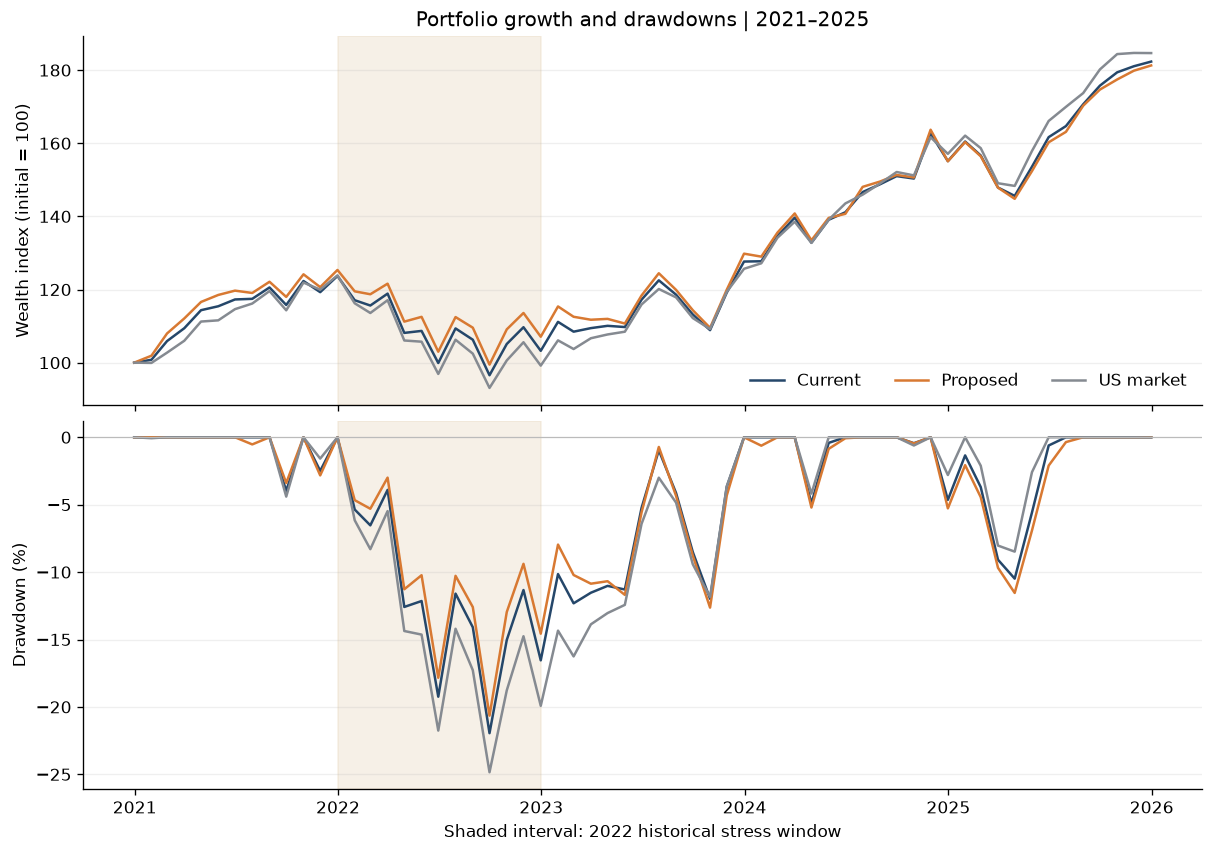

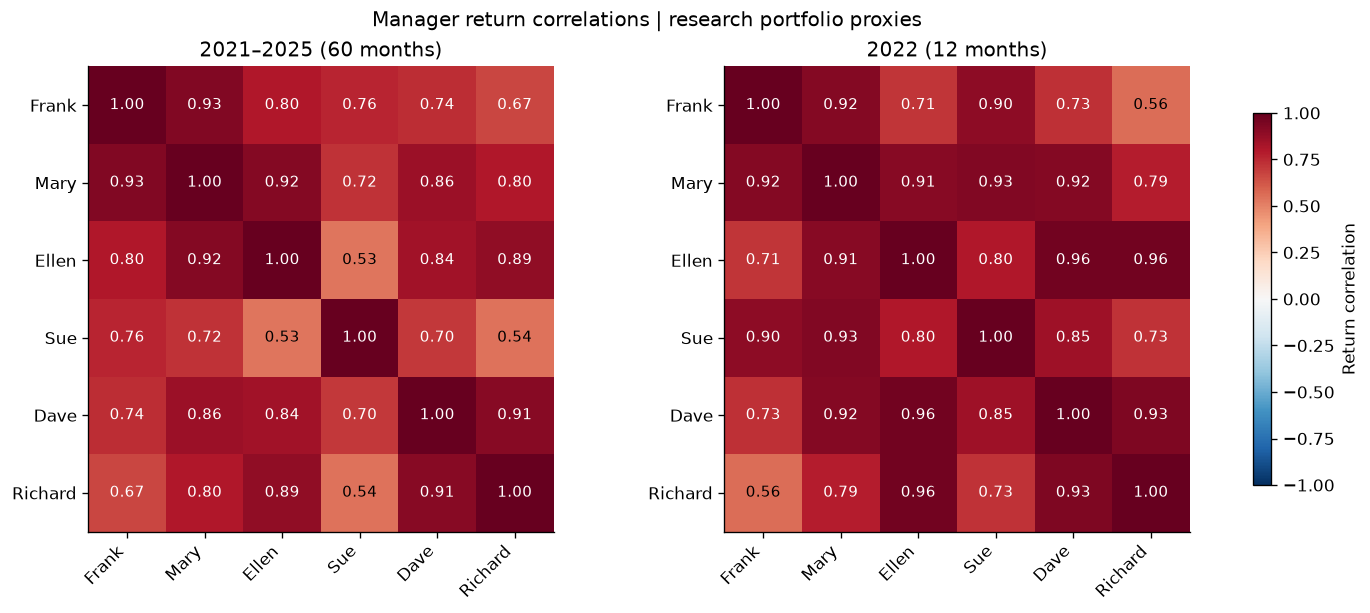

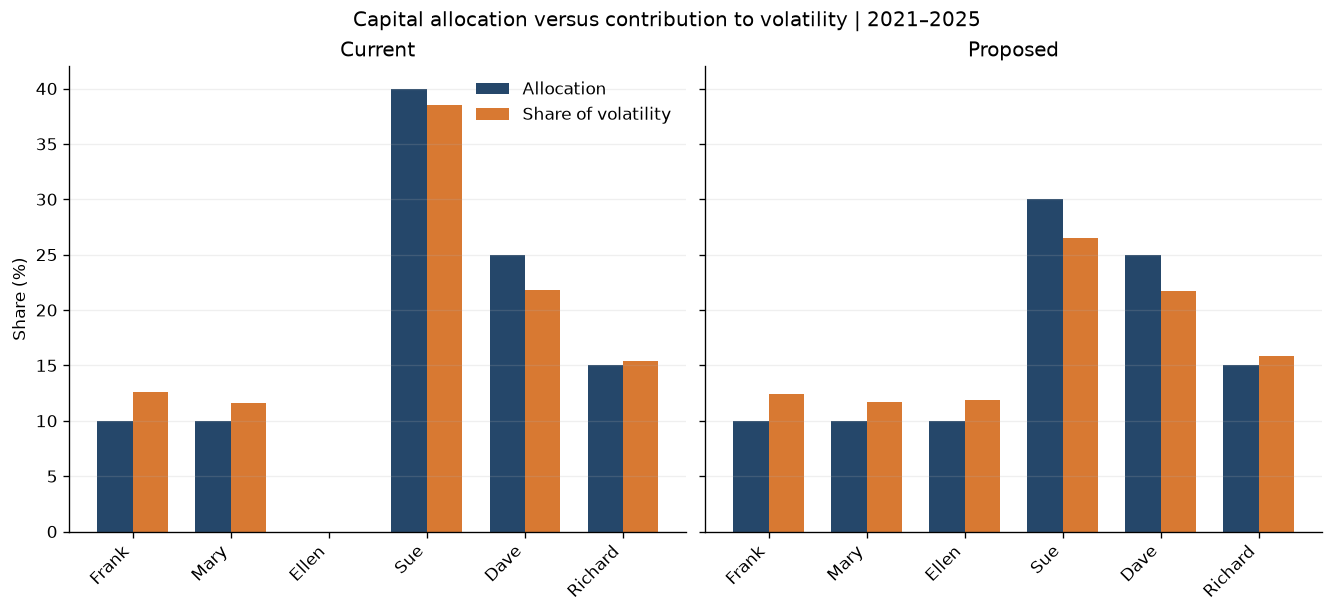

In [9]:
colors = {"Current": "#25476A", "Proposed": "#D87932", "US market": "#858A91"}
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
for name in portfolio_returns.columns:
    axes[0].plot(wealth.index, wealth[name] * 100, label=name, color=colors[name])
    axes[1].plot(drawdown.index, drawdown[name] * 100, label=name, color=colors[name])
axes[0].set_title("Portfolio growth and drawdowns | 2021–2025")
axes[0].set_ylabel("Wealth index (initial = 100)")
axes[0].legend(frameon=False, ncol=3)
axes[1].set_ylabel("Drawdown (%)")
axes[1].axhline(0, color="#BBBBBB", linewidth=0.7)
for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="#E8D6BD", alpha=0.35)
    ax.grid(axis="y", alpha=0.2)
axes[1].set_xlabel("Shaded interval: 2022 historical stress window")
fig.savefig(OUTPUT_DIR / "01_performance_and_drawdown.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, matrix, title in zip(axes, [correlation, stress_correlation],
                             ["2021–2025 (60 months)", "2022 (12 months)"]):
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(6), labels=manager_names.tolist(), rotation=45, ha="right")
    ax.set_yticks(range(6), labels=manager_names.tolist())
    ax.set_title(title)
    for row in range(6):
        for col in range(6):
            value = matrix.iloc[row, col]
            ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                    color="white" if abs(value) > 0.65 else "black", fontsize=9)
fig.colorbar(image, ax=axes, label="Return correlation", shrink=0.8)
fig.suptitle("Manager return correlations | research portfolio proxies")
fig.savefig(OUTPUT_DIR / "02_manager_correlations.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, constrained_layout=True)
positions = np.arange(6)
for ax, scenario in zip(axes, scenarios):
    data = risk_contributions[risk_contributions["scenario"] == scenario]
    ax.bar(positions - 0.18, data["allocation_weight"] * 100, width=0.36, label="Allocation", color="#25476A")
    ax.bar(positions + 0.18, data["risk_share"] * 100, width=0.36, label="Share of volatility", color="#D87932")
    ax.set_xticks(positions, labels=data["manager_name"], rotation=45, ha="right")
    ax.set_title(scenario)
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Share (%)")
axes[0].legend(frameon=False)
fig.suptitle("Capital allocation versus contribution to volatility | 2021–2025")
fig.savefig(OUTPUT_DIR / "03_allocation_and_risk.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 10. Export results and record the inputs

Exported returns, weights and risk shares remain decimals; chart labels use
percentages. `change_percentage_points` is already multiplied by 100. P&L is USD.
These exports can feed the later dashboards. Re-running replaces these derived
outputs, not the source CSVs. Input hashes identify the exact files analysed.

In [10]:
metrics.to_csv(OUTPUT_DIR / "portfolio_metrics.csv")
stress_metrics.to_csv(OUTPUT_DIR / "stress_2022.csv")
comparison.to_csv(OUTPUT_DIR / "scenario_comparison.csv", index=False)
portfolio_returns.to_csv(OUTPUT_DIR / "monthly_portfolio_returns.csv")
wealth.to_csv(OUTPUT_DIR / "wealth_index.csv")
drawdown.to_csv(OUTPUT_DIR / "drawdowns.csv")
risk_contributions.to_csv(OUTPUT_DIR / "risk_contributions.csv", index=False)
correlation.to_csv(OUTPUT_DIR / "manager_correlations.csv")
stress_correlation.to_csv(OUTPUT_DIR / "manager_correlations_2022.csv")
candidate_correlations.to_csv(OUTPUT_DIR / "candidate_correlations.csv", index=False)

input_hashes = {}
for filename in ["managers.csv", "manager_returns.csv", "allocations.csv", "market_data.csv"]:
    input_hashes[filename] = hashlib.sha256((DATA_DIR / filename).read_bytes()).hexdigest()
run_details = {
    "python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
    "analysis_period": "2021-01 to 2025-12", "stress_period": "2022-01 to 2022-12",
    "rebalancing": "monthly to target weights", "return_units": "decimal",
    "input_sha256": input_hashes
}
(OUTPUT_DIR / "run_details.json").write_text(json.dumps(run_details, indent=2))
print("Export complete: 10 CSV tables, 3 PNG charts and run_details.json.")

Export complete: 10 CSV tables, 3 PNG charts and run_details.json.


## 11. Interpret the trade-off

A candidate does not need to improve every metric to be worth investigating.
Evaluate return, volatility, drawdown and stress performance together. Strong
historical stress performance cannot be assumed to repeat. Reducing Sue's
allocation also resolves the illustrative 35% manager allocation breach, but
that policy improvement is separate from the portfolio's measured risk change.

Before a real allocation decision, diligence would need actual manager holdings,
strategy process, fees, capacity and trading costs. Research proxies cannot
establish actual manager skill. Small/value exposure is still equity exposure.

In [11]:
delta_vol = comparison.loc[comparison["metric"] == "Annualized volatility", "change_percentage_points"].iloc[0]
delta_return = comparison.loc[comparison["metric"] == "Annualized return", "change_percentage_points"].iloc[0]
delta_drawdown = comparison.loc[comparison["metric"] == "Maximum drawdown", "change_percentage_points"].iloc[0]
delta_stress = comparison.loc[comparison["metric"] == "2022 return", "change_percentage_points"].iloc[0]

print(f"Proposed minus Current: annualized return {delta_return:+.2f} percentage points.")
print(f"Proposed minus Current: annualized volatility {delta_vol:+.2f} percentage points.")
print(f"Proposed minus Current: maximum drawdown {delta_drawdown:+.2f} percentage points (positive = shallower).")
print(f"Proposed minus Current: 2022 return {delta_stress:+.2f} percentage points.")

Proposed minus Current: annualized return -0.13 percentage points.
Proposed minus Current: annualized volatility +0.38 percentage points.
Proposed minus Current: maximum drawdown +1.30 percentage points (positive = shallower).
Proposed minus Current: 2022 return +1.98 percentage points.


## Sources and scope

- [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)
- [Portfolio construction](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/six_portfolios.html)
- [Factor definitions](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html)
- [pandas covariance](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.cov.html)

The prepared data use the August 2026 CRSP vintage. All six strategies are U.S.
equity research portfolios. This study does not measure hedge-fund liquidity,
leverage, derivatives or counterparty risk. 